<a href="https://colab.research.google.com/github/khalilinsights/Eco-Move-Mobility/blob/main/EcoMobility.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q streamlit plotly openpyxl seaborn

In [3]:
import pandas as pd
import numpy as np

DATA = "/content/[5442] EcoMoveMobility.xlsx"

raw = pd.read_excel(DATA, sheet_name="Dataset")
print("Rows, columns:", raw.shape)
print()
print(raw.dtypes)
raw.head()

Rows, columns: (5000, 18)

Record_ID                    object
Date                          int64
City                         object
Country                      object
Transport_Mode               object
Route_Type                   object
Weather                      object
Event_Day                    object
Passengers                    int64
Trips                         int64
Average_Delay_Minutes       float64
On_Time_Percentage          float64
Ticket_Revenue_EUR          float64
Operating_Cost_EUR          float64
CO2_Saved_KG                float64
Energy_Consumption_KWh      float64
Customer_Rating             float64
Accessibility_Complaints      int64
dtype: object


,Record_ID,Date,City,Country,Transport_Mode,Route_Type,Weather,Event_Day,Passengers,Trips,Average_Delay_Minutes,On_Time_Percentage,Ticket_Revenue_EUR,Operating_Cost_EUR,CO2_Saved_KG,Energy_Consumption_KWh,Customer_Rating,Accessibility_Complaints
0,EM-00001,45747,Paris,France,Tram,Tourist Zone,Cloudy,Yes,22946,101,3.2,85.1,58846.34,47796.73,2005.0,1446.4,4.4,26
1,EM-00002,45717,Paris,France,Tram,University Area,Cloudy,No,9417,59,1.5,90.1,24578.85,20708.01,824.3,495.1,4.7,7
2,EM-00003,45882,Rotterdam,Netherlands,Tram,Airport Connector,Clear,No,6467,38,3.4,87.9,15168.68,14129.41,693.1,405.8,4.4,7
3,EM-00004,45504,Lyon,France,Tram,University Area,Clear,Yes,5218,33,6.9,74.5,14172.20,11945.52,600.1,278.1,3.9,7
4,EM-00005,45578,Amsterdam,Netherlands,Metro,Tourist Zone,Cloudy,No,10258,19,3.6,83.2,27534.92,28846.82,1392.4,580.5,4.4,12


In [4]:
print("Missing values in total:", int(raw.isna().sum().sum()))
print("Duplicate rows:", int(raw.duplicated().sum()))
print("Duplicate Record_IDs:", int(raw["Record_ID"].duplicated().sum()))
print()
print("Unique values: cities =", raw["City"].nunique(), "| countries =", raw["Country"].nunique(),
      "| modes =", raw["Transport_Mode"].nunique(), "| weather types =", raw["Weather"].nunique())
print()
# Demand is very skewed: this motivates the log scale in Figure 5
print("Passengers per record: min =", raw["Passengers"].min(), "| max =", raw["Passengers"].max(),
      "| median =", raw["Passengers"].median())
raw.describe().T.round(2)

Missing values in total: 0
Duplicate rows: 0
Duplicate Record_IDs: 0

Unique values: cities = 12 | countries = 6 | modes = 6 | weather types = 6

Passengers per record: min = 64 | max = 66416 | median = 4398.0


,count,mean,std,min,25%,50%,75%,max
Date,5000.0,45653.87,209.72,45292.00,45474.00,45648.00,45835.00,46022.00
Passengers,5000.0,8181.94,10018.72,64.00,1411.75,4398.00,10077.50,66416.00
Trips,5000.0,121.77,155.79,11.00,36.00,52.00,106.00,1048.00
Average_Delay_Minutes,5000.0,4.35,2.39,0.00,2.60,4.40,6.00,12.50
On_Time_Percentage,5000.0,82.06,7.93,55.00,76.50,82.00,87.90,99.00
Ticket_Revenue_EUR,5000.0,22328.12,28822.41,90.93,3280.33,11190.02,26329.65,204386.05
Operating_Cost_EUR,5000.0,22422.00,26114.32,978.37,7189.86,11638.28,22732.98,178936.39
CO2_Saved_KG,5000.0,896.39,1261.16,8.30,126.85,338.30,1009.48,8884.10
Energy_Consumption_KWh,5000.0,466.81,564.22,0.00,85.20,269.70,599.62,3856.30
Customer_Rating,5000.0,4.01,0.40,2.70,3.70,4.00,4.30,4.90


In [5]:
df = raw.copy()

# 1) Excel serial dates -> real datetimes, plus a monthly period for time-series aggregation
df["Date"] = pd.to_datetime(df["Date"], origin="1899-12-30", unit="D")
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()

# 2) Engineered KPIs
df["Profit_EUR"] = df["Ticket_Revenue_EUR"] - df["Operating_Cost_EUR"]       # revenue minus cost
df["Cost_Recovery"] = df["Ticket_Revenue_EUR"] / df["Operating_Cost_EUR"]     # revenue divided by cost

print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Records with a loss (Profit < 0): %.1f%%" % ((df["Profit_EUR"] < 0).mean() * 100))
print("Net profit over two years: EUR %.2f million" % (df["Profit_EUR"].sum() / 1e6))
df[["Date", "Month", "Ticket_Revenue_EUR", "Operating_Cost_EUR", "Profit_EUR", "Cost_Recovery"]].head()

Date range: 2024-01-01 to 2025-12-31
Records with a loss (Profit < 0): 45.4%
Net profit over two years: EUR -0.47 million


,Date,Month,Ticket_Revenue_EUR,Operating_Cost_EUR,Profit_EUR,Cost_Recovery
0,2025-03-31,2025-03-01,58846.34,47796.73,11049.61,1.231179
1,2025-03-01,2025-03-01,24578.85,20708.01,3870.84,1.186925
2,2025-08-13,2025-08-01,15168.68,14129.41,1039.27,1.073554
3,2024-07-31,2024-07-01,14172.20,11945.52,2226.68,1.186403
4,2024-10-13,2024-10-01,27534.92,28846.82,-1311.90,0.954522


In [8]:
%%writefile prep.py

import os
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

DATA = "/content/[5442] EcoMoveMobility.xlsx"

INK      = "#1a2330"
SUB      = "#5b6472"
GRID     = "#dfe3e8"
ACCENT   = "#0b7285"
WARN     = "#c92a2a"
GOOD     = "#2f9e44"
QUAL = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9",
        "#F0E442", "#999999"]


def load():
    """Load the dataset, fix the Excel date serials and add derived KPIs."""
    df = pd.read_excel(DATA, sheet_name="Dataset")
    df["Date"] = pd.to_datetime(df["Date"], origin="1899-12-30", unit="D")
    df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()
    # Financial sustainability metrics
    df["Profit_EUR"] = df["Ticket_Revenue_EUR"] - df["Operating_Cost_EUR"]
    df["Cost_Recovery"] = df["Ticket_Revenue_EUR"] / df["Operating_Cost_EUR"]
    return df


def set_style():
    sns.set_theme(style="white")
    mpl.rcParams.update({
        "font.family": "DejaVu Sans",
        "font.size": 11,
        "axes.edgecolor": GRID,
        "axes.linewidth": 1.0,
        "axes.titlesize": 13,
        "axes.labelcolor": INK,
        "text.color": INK,
        "xtick.color": SUB,
        "ytick.color": SUB,
        "figure.dpi": 150,
        "savefig.dpi": 200,
        "savefig.bbox": "tight",
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    })


def titles(ax, title, subtitle=None, source="Source: EcoMove City Transport Authority (2024–2025), n = 5,000 records."):
    """Add a bold title, muted subtitle and a small source note."""
    ax.set_title("")
    fig = ax.get_figure()
    fig.text(0.008, 1.02, title, fontsize=15, fontweight="bold",
             color=INK, ha="left", va="bottom", transform=ax.transAxes)
    if subtitle:
        fig.text(0.008, 0.995, subtitle, fontsize=10.5, color=SUB,
                 ha="left", va="top", transform=ax.transAxes)
    if source:
        fig.text(0.008, -0.14, source, fontsize=8.2, color=SUB,
                 ha="left", va="top", transform=ax.transAxes)


def clean_axes(ax, grid_axis="y"):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.9, zorder=0)
    ax.set_axisbelow(True)

os.makedirs("figs", exist_ok=True)

Overwriting prep.py


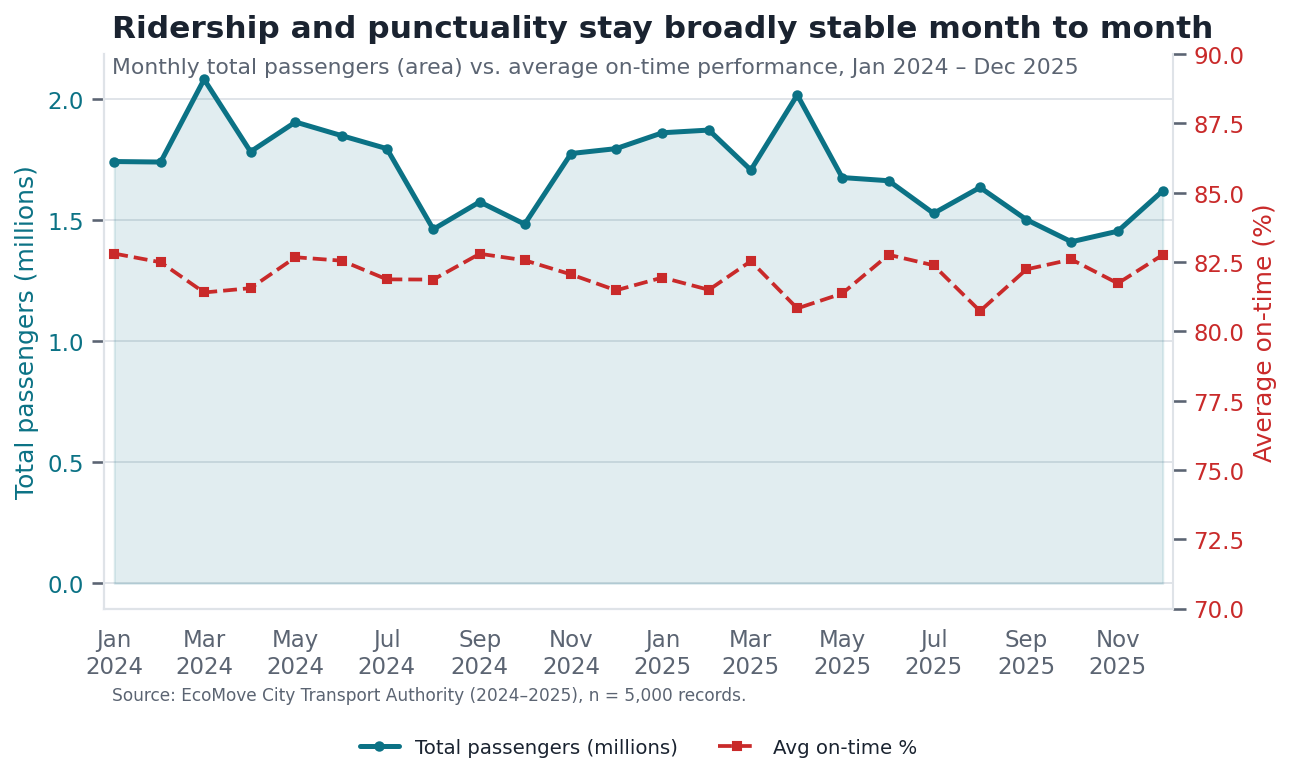

fig1 done (24, 4)


In [9]:
"""FIG 1 - Time-series: monthly ridership trend with on-time reliability overlay."""
import sys
import importlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Force reload prep.py to apply the correct path configuration
import prep
importlib.reload(prep)
from prep import load, set_style, titles, clean_axes, ACCENT, WARN, SUB, INK

set_style()
df = load()

m = df.groupby("Month").agg(Passengers=("Passengers", "sum"),
                            OnTime=("On_Time_Percentage", "mean")).reset_index()
m["Passengers_m"] = m["Passengers"] / 1e6  # millions

fig, ax1 = plt.subplots(figsize=(9.2, 4.8))
ax1.fill_between(m["Month"], m["Passengers_m"], color=ACCENT, alpha=0.12, zorder=1)
ax1.plot(m["Month"], m["Passengers_m"], color=ACCENT, lw=2.4, marker="o",
         ms=4, zorder=3, label="Total passengers (millions)")
ax1.set_ylabel("Total passengers (millions)", color=ACCENT)
ax1.tick_params(axis="y", labelcolor=ACCENT)
clean_axes(ax1, grid_axis="y")

ax2 = ax1.twinx()
ax2.plot(m["Month"], m["OnTime"], color=WARN, lw=1.8, ls="--",
         marker="s", ms=3.5, zorder=3, label="Avg on-time %")
ax2.set_ylabel("Average on-time (%)", color=WARN)
ax2.tick_params(axis="y", labelcolor=WARN)
ax2.set_ylim(70, 90)
for s in ["top"]:
    ax2.spines[s].set_visible(False)

ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax1.margins(x=0.01)

lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], loc="lower center",
           bbox_to_anchor=(0.5, -0.30), ncol=2, frameon=False, fontsize=9.5)

titles(ax1, "Ridership and punctuality stay broadly stable month to month",
        "Monthly total passengers (area) vs. average on-time performance, Jan 2024 – Dec 2025")
plt.savefig("figs/fig1_timeseries.png")
plt.show()
print("fig1 done", m.shape)

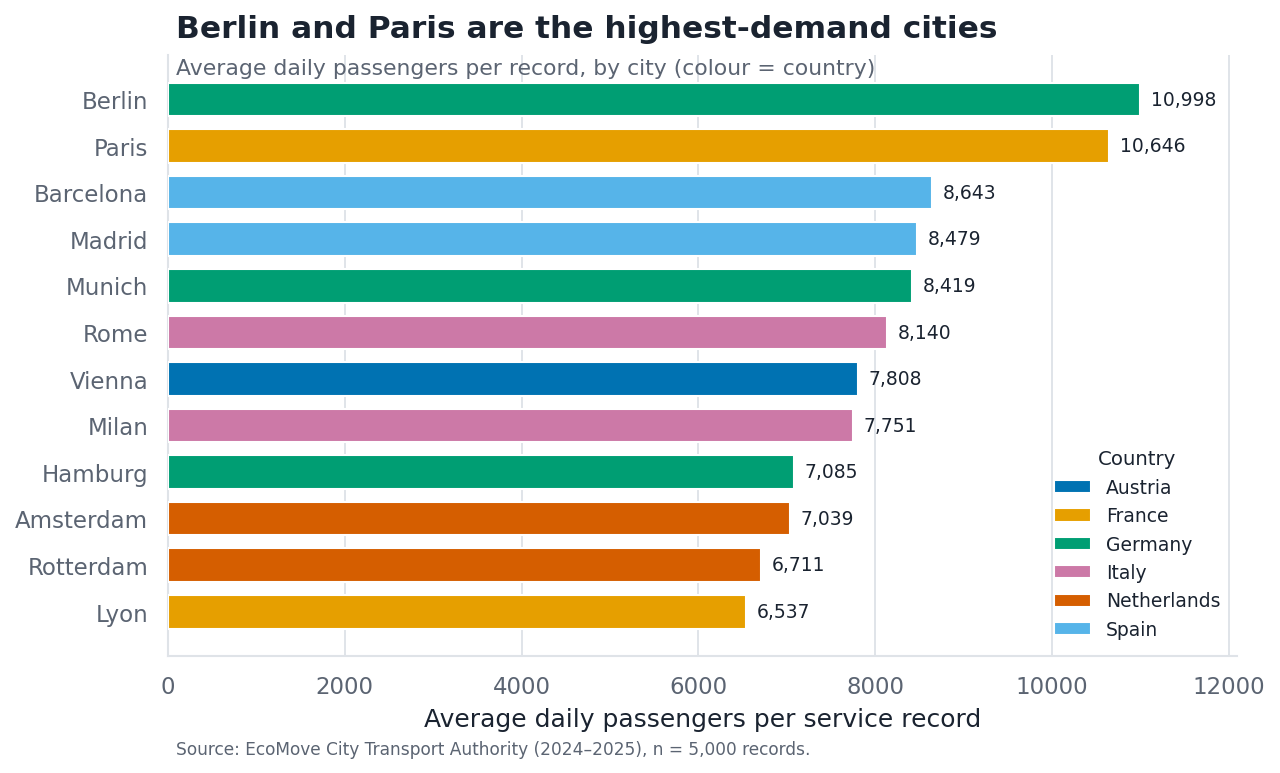

fig2 done


In [10]:
"""FIG 2 - Comparison: average daily passengers by city, grouped by country."""
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from prep import load, set_style, titles, clean_axes, QUAL, INK, SUB

set_style()
df = load()

c = (df.groupby(["Country", "City"])["Passengers"].mean()
       .reset_index().sort_values("Passengers", ascending=True))
countries = sorted(df["Country"].unique())
cmap = {co: QUAL[i] for i, co in enumerate(countries)}
colors = c["Country"].map(cmap)

fig, ax = plt.subplots(figsize=(9.2, 5.2))
bars = ax.barh(c["City"], c["Passengers"], color=colors, zorder=3, height=0.72)
clean_axes(ax, grid_axis="x")
ax.set_xlabel("Average daily passengers per service record")
ax.set_ylabel("")

for b, v in zip(bars, c["Passengers"]):
    ax.text(b.get_width() + 120, b.get_y() + b.get_height()/2,
            f"{v:,.0f}", va="center", ha="left", fontsize=9, color=INK)
ax.margins(x=0.10)

handles = [Patch(facecolor=cmap[co], label=co) for co in countries]
ax.legend(handles=handles, title="Country", loc="lower right",
          frameon=False, fontsize=9, title_fontsize=9.5)

titles(ax, "Berlin and Paris are the highest-demand cities",
        "Average daily passengers per record, by city (colour = country)")
plt.savefig("figs/fig2_comparison.png")
plt.show()
print("fig2 done")

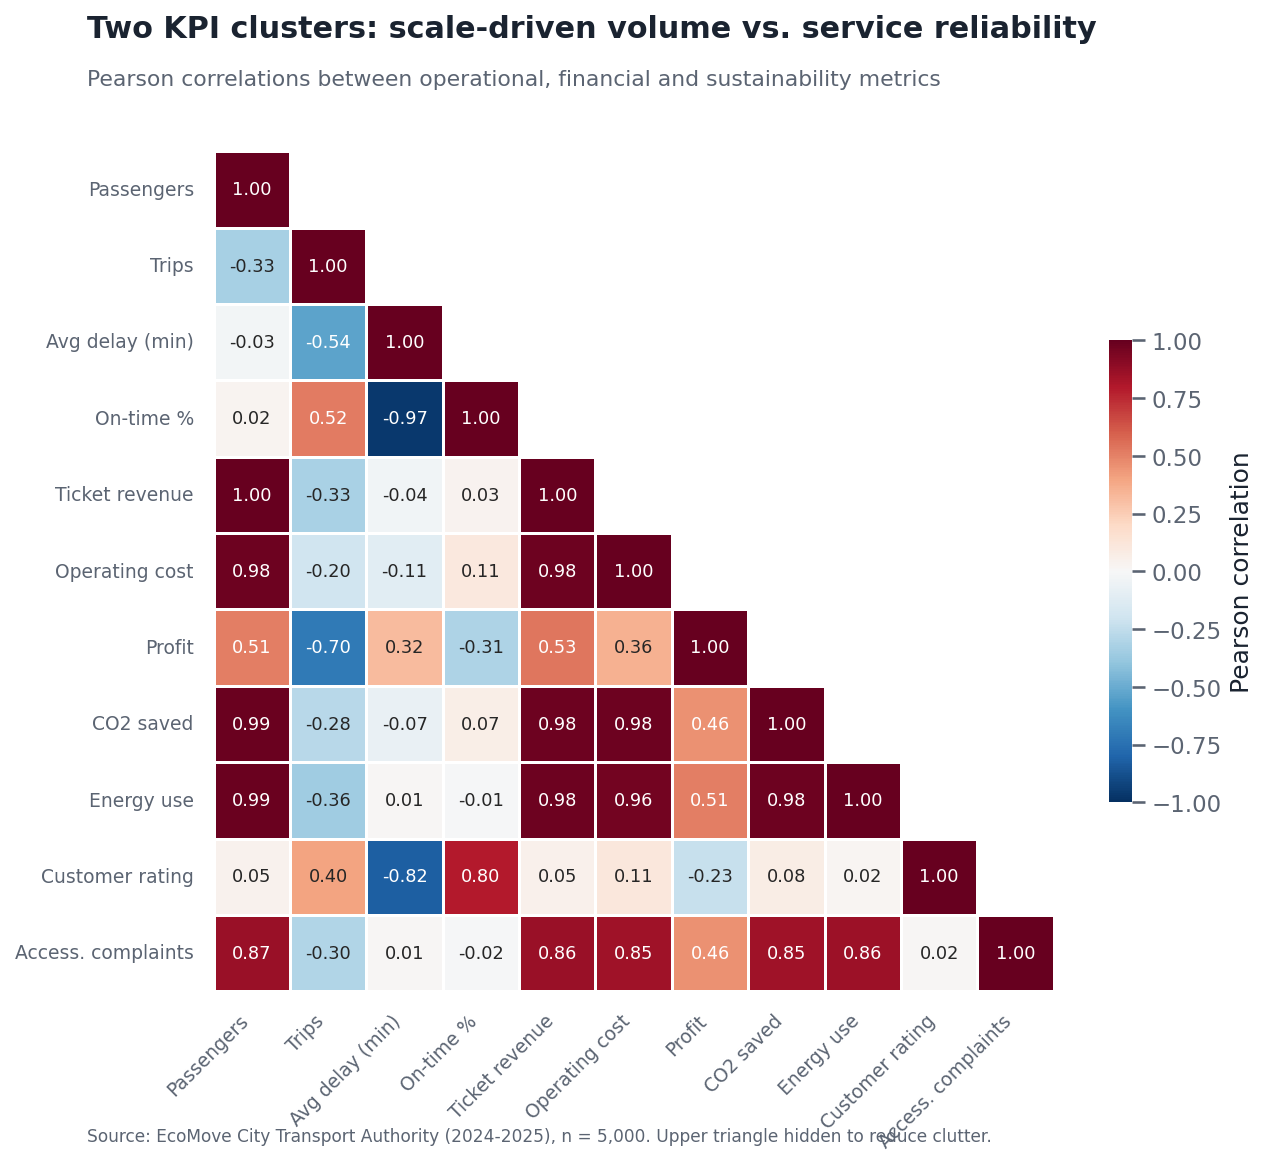

fig3 done


In [11]:
"""FIG 3 - Relationship (overview): correlation heatmap of key numeric KPIs."""
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from prep import load, set_style, INK, SUB

set_style()
df = load()

cols = ["Passengers", "Trips", "Average_Delay_Minutes", "On_Time_Percentage",
        "Ticket_Revenue_EUR", "Operating_Cost_EUR", "Profit_EUR",
        "CO2_Saved_KG", "Energy_Consumption_KWh", "Customer_Rating",
        "Accessibility_Complaints"]
labels = ["Passengers", "Trips", "Avg delay (min)", "On-time %",
          "Ticket revenue", "Operating cost", "Profit",
          "CO2 saved", "Energy use", "Customer rating", "Access. complaints"]
corr = df[cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9.0, 8.0))
fig.subplots_adjust(top=0.86, bottom=0.16, left=0.16, right=0.98)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8.5},
            square=True, linewidths=0.6, linecolor="white",
            cbar_kws={"shrink": 0.55, "label": "Pearson correlation"},
            xticklabels=labels, yticklabels=labels, ax=ax)
ax.tick_params(labelsize=9)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)

fig.text(0.10, 0.955, "Two KPI clusters: scale-driven volume vs. service reliability",
         fontsize=14.5, fontweight="bold", color=INK, ha="left")
fig.text(0.10, 0.915, "Pearson correlations between operational, financial and sustainability metrics",
         fontsize=10.5, color=SUB, ha="left")
fig.text(0.10, 0.035,
         "Source: EcoMove City Transport Authority (2024-2025), n = 5,000. Upper triangle hidden to reduce clutter.",
         fontsize=8.2, color=SUB, ha="left")
plt.savefig("figs/fig3_heatmap.png")
plt.show()
print("fig3 done")

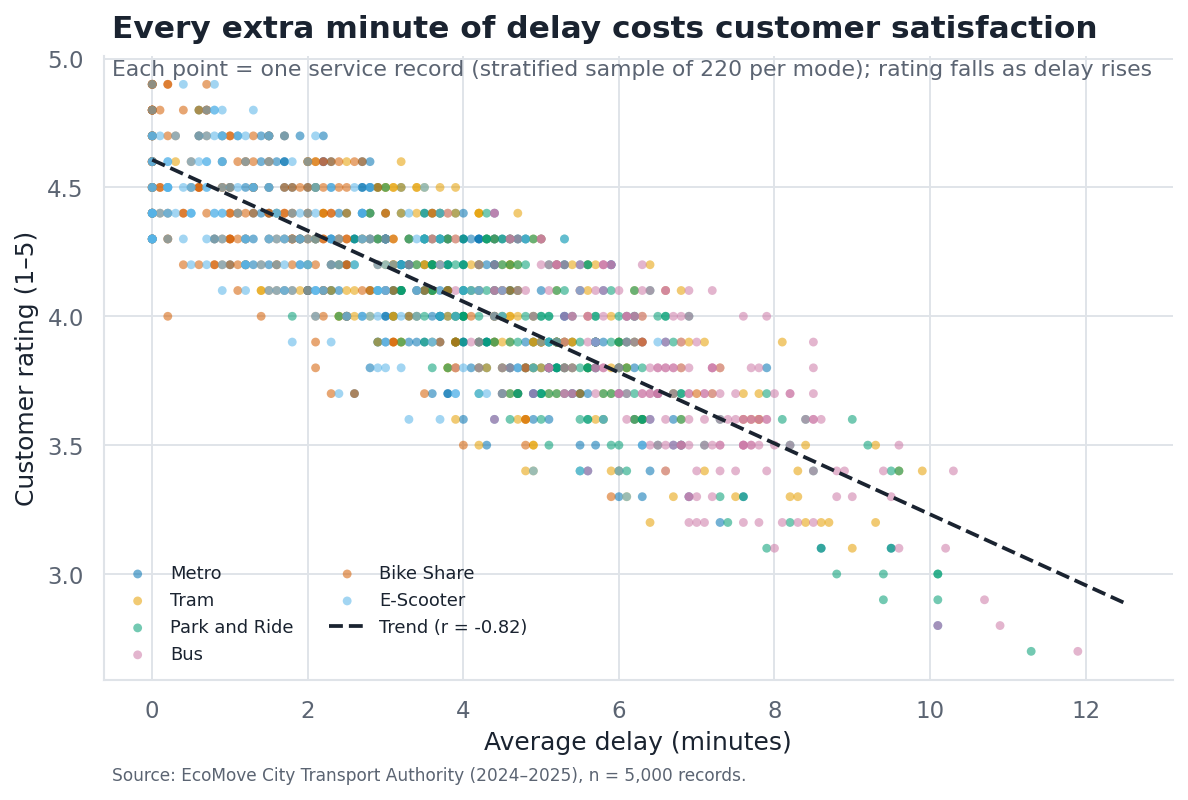

fig4 done


In [12]:
"""FIG 4 - Relationship: delay vs customer rating, coloured by transport mode."""
import matplotlib.pyplot as plt
import numpy as np
from prep import load, set_style, titles, clean_axes, QUAL, SUB, INK

set_style()
df = load()

modes = ["Metro", "Tram", "Park and Ride", "Bus", "Bike Share", "E-Scooter"]
cmap = {m: QUAL[i] for i, m in enumerate(modes)}

fig, ax = plt.subplots(figsize=(9.2, 5.4))
# light sample per mode to avoid overplotting while keeping shape
for m in modes:
    d = df[df["Transport_Mode"] == m].sample(min(220, (df["Transport_Mode"] == m).sum()),
                                             random_state=1)
    ax.scatter(d["Average_Delay_Minutes"], d["Customer_Rating"],
               s=18, alpha=0.55, color=cmap[m], label=m, edgecolors="none", zorder=3)

# overall trend line
z = np.polyfit(df["Average_Delay_Minutes"], df["Customer_Rating"], 1)
xs = np.linspace(df["Average_Delay_Minutes"].min(), df["Average_Delay_Minutes"].max(), 50)
ax.plot(xs, np.poly1d(z)(xs), color=INK, lw=1.8, ls="--", zorder=4,
        label=f"Trend (r = {df['Average_Delay_Minutes'].corr(df['Customer_Rating']):.2f})")

clean_axes(ax, grid_axis="both")
ax.set_xlabel("Average delay (minutes)")
ax.set_ylabel("Customer rating (1–5)")
ax.legend(loc="lower left", frameon=False, fontsize=8.6, ncol=2)

titles(ax, "Every extra minute of delay costs customer satisfaction",
        "Each point = one service record (stratified sample of 220 per mode); rating falls as delay rises")
plt.savefig("figs/fig4_scatter.png")
plt.show()
print("fig4 done")

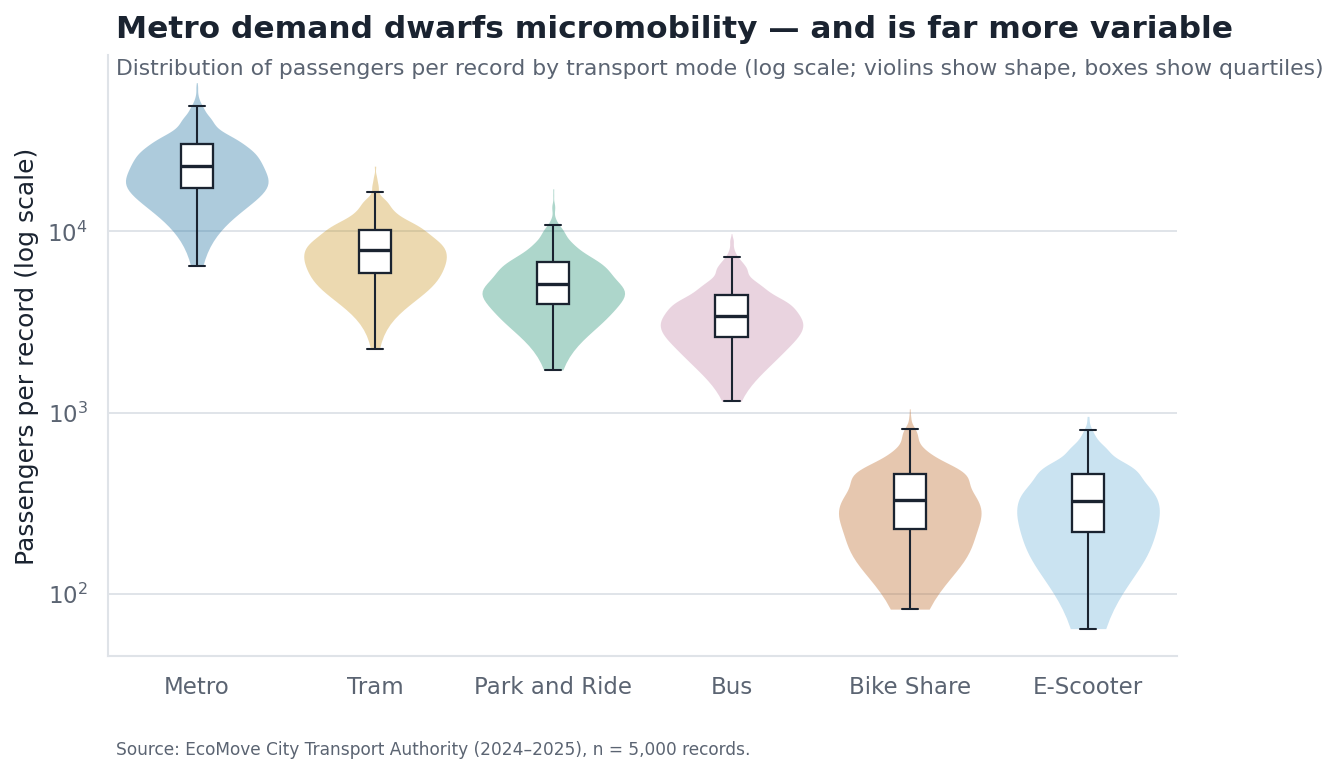

fig5 done


In [13]:
"""FIG 5 - Distribution: passenger demand by transport mode (violin + box, log scale)."""
import matplotlib.pyplot as plt
import seaborn as sns
from prep import load, set_style, titles, clean_axes, QUAL, SUB, INK

set_style()
df = load()

order = (df.groupby("Transport_Mode")["Passengers"].median()
           .sort_values(ascending=False).index.tolist())
pal = {m: QUAL[i] for i, m in enumerate(order)}

fig, ax = plt.subplots(figsize=(9.2, 5.2))
sns.violinplot(data=df, x="Transport_Mode", y="Passengers", order=order,
               hue="Transport_Mode", palette=pal, legend=False,
               inner=None, cut=0, linewidth=0, alpha=0.35, ax=ax)
sns.boxplot(data=df, x="Transport_Mode", y="Passengers", order=order,
            width=0.18, showfliers=False, ax=ax,
            boxprops={"facecolor": "white", "edgecolor": INK, "linewidth": 1.1},
            medianprops={"color": INK, "linewidth": 1.6},
            whiskerprops={"color": INK}, capprops={"color": INK})
ax.set_yscale("log")
ax.set_ylabel("Passengers per record (log scale)")
ax.set_xlabel("")
clean_axes(ax, grid_axis="y")

titles(ax, "Metro demand dwarfs micromobility — and is far more variable",
        "Distribution of passengers per record by transport mode (log scale; violins show shape, boxes show quartiles)")
plt.savefig("figs/fig5_distribution.png")
plt.show()
print("fig5 done")

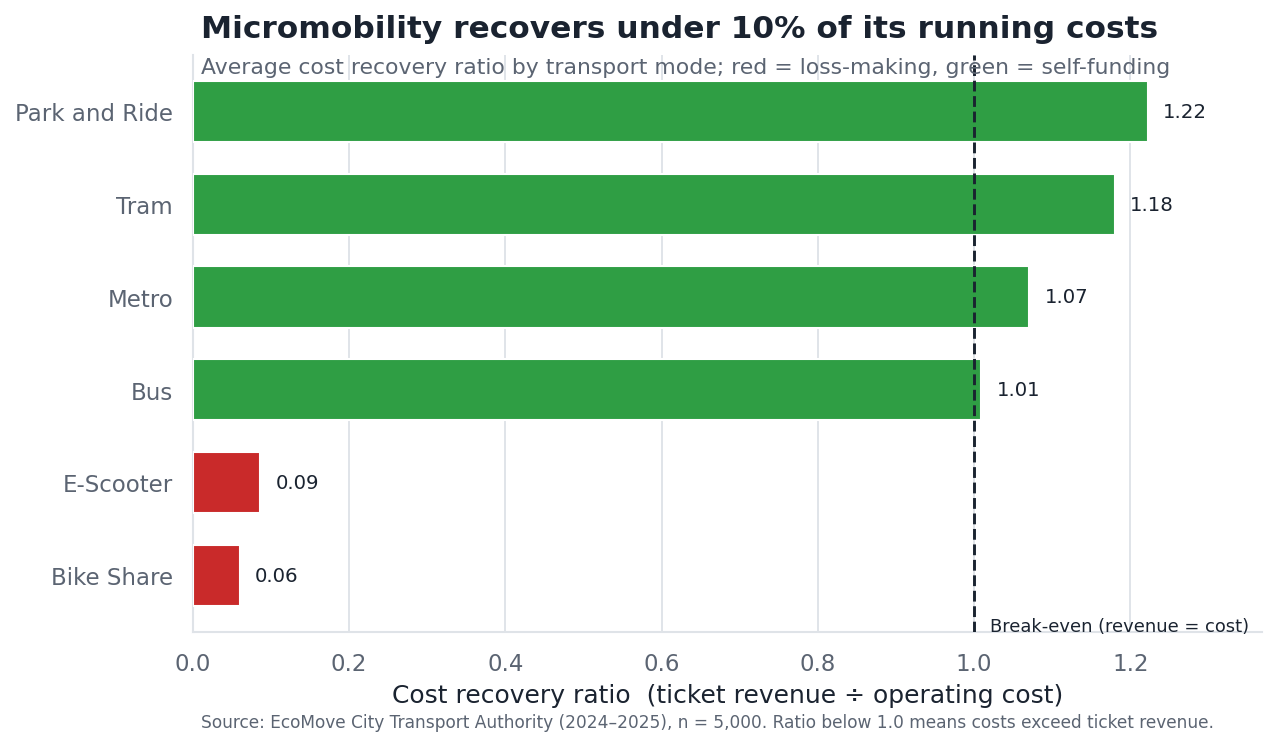

fig6 done


In [14]:
"""FIG 6 - Performance indicator: cost recovery ratio by transport mode."""
import matplotlib.pyplot as plt
from prep import load, set_style, titles, clean_axes, GOOD, WARN, SUB, INK

set_style()
df = load()

r = (df.groupby("Transport_Mode")["Cost_Recovery"].mean()
       .sort_values().reset_index())
colors = [GOOD if v >= 1 else WARN for v in r["Cost_Recovery"]]

fig, ax = plt.subplots(figsize=(9.2, 5.0))
bars = ax.barh(r["Transport_Mode"], r["Cost_Recovery"], color=colors,
               zorder=3, height=0.66)
ax.axvline(1.0, color=INK, lw=1.4, ls="--", zorder=4)
ax.text(1.02, -0.6, "Break-even (revenue = cost)", fontsize=8.6, color=INK)
clean_axes(ax, grid_axis="x")
ax.set_xlabel("Cost recovery ratio  (ticket revenue ÷ operating cost)")
ax.set_ylabel("")

for b, v in zip(bars, r["Cost_Recovery"]):
    ax.text(b.get_width() + 0.02, b.get_y() + b.get_height()/2,
            f"{v:.2f}", va="center", ha="left", fontsize=9.5, color=INK)
ax.margins(x=0.12)

titles(ax, "Micromobility recovers under 10% of its running costs",
        "Average cost recovery ratio by transport mode; red = loss-making, green = self-funding",
        source="Source: EcoMove City Transport Authority (2024–2025), n = 5,000. Ratio below 1.0 means costs exceed ticket revenue.")
plt.savefig("figs/fig6_performance.png")
plt.show()
print("fig6 done")

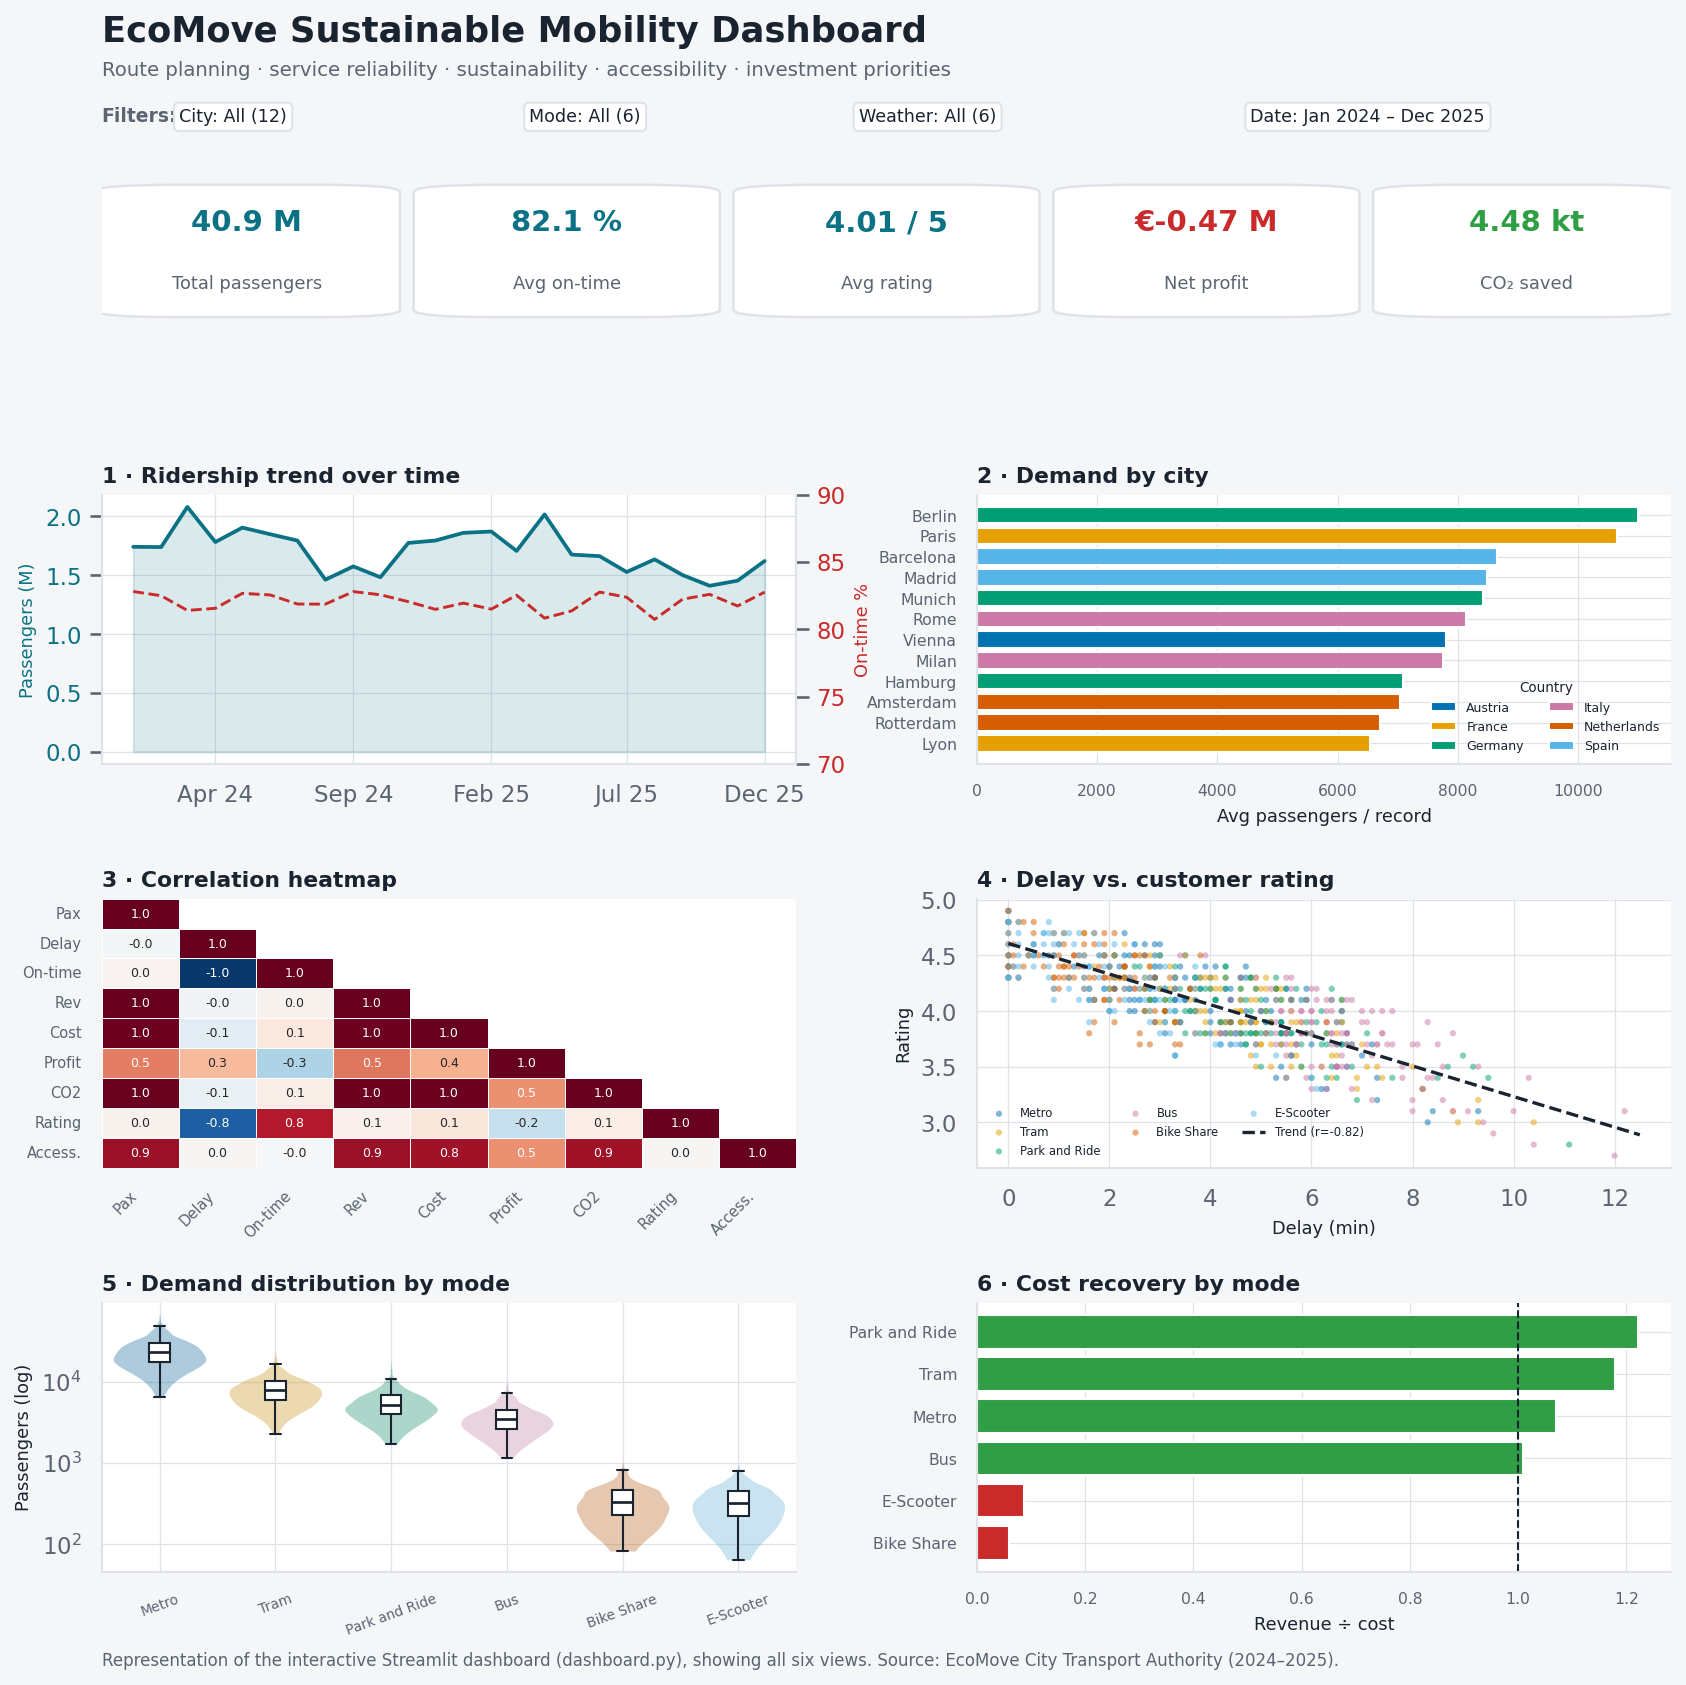

fig7 (6 views, matched styling) rendered OK


In [15]:
"""FIG 7 - Static composite mirroring the Streamlit dashboard: all SIX views,
styled to match the six standalone figures (Figures 1-6)."""
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch, Patch
import numpy as np
import seaborn as sns
from prep import load, set_style, QUAL, ACCENT, WARN, GOOD, INK, SUB, GRID
import os

set_style()
df = load()

fig = plt.figure(figsize=(11.5, 11.4))
fig.patch.set_facecolor("#f4f6f8")
gs = GridSpec(3, 2, figure=fig, hspace=0.50, wspace=0.26,
              left=0.06, right=0.97, top=0.70, bottom=0.07)

# ---- Header ----
fig.text(0.06, 0.965, "EcoMove Sustainable Mobility Dashboard",
         fontsize=17, fontweight="bold", color=INK)
fig.text(0.06, 0.945, "Route planning · service reliability · sustainability · accessibility · investment priorities",
         fontsize=9.5, color=SUB)
chips = ["Filters:", "City: All (12)", "Mode: All (6)", "Weather: All (6)", "Date: Jan 2024 – Dec 2025"]
x = 0.06
for i, ch in enumerate(chips):
    if i == 0:
        fig.text(x, 0.918, ch, fontsize=9, color=SUB, fontweight="bold"); x += 0.045
        continue
    fig.text(x, 0.918, ch, fontsize=8.4, color=INK,
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=GRID, lw=1))
    x += 0.012 * len(ch) + 0.035

# ---- KPI cards ----
kpis = [("Total passengers", f"{df['Passengers'].sum()/1e6:,.1f} M", ACCENT),
        ("Avg on-time", f"{df['On_Time_Percentage'].mean():.1f} %", ACCENT),
        ("Avg rating", f"{df['Customer_Rating'].mean():.2f} / 5", ACCENT),
        ("Net profit", f"€{(df['Ticket_Revenue_EUR'].sum()-df['Operating_Cost_EUR'].sum())/1e6:,.2f} M", WARN),
        ("CO₂ saved", f"{df['CO2_Saved_KG'].sum()/1e6:,.2f} kt", GOOD)]
kax = fig.add_axes([0.06, 0.80, 0.91, 0.085]); kax.axis("off")
kax.set_xlim(0, 1); kax.set_ylim(0, 1)
n = len(kpis); w = 0.185; gap = (1 - n*w) / (n-1)
for i, (lab, val, col) in enumerate(kpis):
    xx = i*(w+gap)
    kax.add_patch(FancyBboxPatch((xx, 0.05), w, 0.9,
                  boxstyle="round,pad=0.005,rounding_size=0.05", fc="white", ec=GRID, lw=1.2))
    kax.text(xx+w/2, 0.64, val, fontsize=14, fontweight="bold", color=col, ha="center")
    kax.text(xx+w/2, 0.24, lab, fontsize=8.6, color=SUB, ha="center")

modes_order = ["Metro", "Tram", "Park and Ride", "Bus", "Bike Share", "E-Scooter"]

def style(ax, title):
    ax.set_title(title, fontsize=10.5, fontweight="bold", loc="left", color=INK, pad=6)
    ax.set_facecolor("white")
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.grid(axis="both", color=GRID, lw=0.6); ax.set_axisbelow(True)

# Panel 1: ridership trend WITH on-time overlay (matches Fig 1)
ax = fig.add_subplot(gs[0, 0])
m = df.groupby("Month").agg(P=("Passengers", "sum"), O=("On_Time_Percentage", "mean")).reset_index()
ax.fill_between(m["Month"], m["P"]/1e6, color=ACCENT, alpha=0.15)
ax.plot(m["Month"], m["P"]/1e6, color=ACCENT, lw=1.8)
ax.set_ylabel("Passengers (M)", fontsize=8.5, color=ACCENT)
ax.tick_params(axis="y", labelcolor=ACCENT)
axb = ax.twinx()
axb.plot(m["Month"], m["O"], color=WARN, lw=1.4, ls="--")
axb.set_ylabel("On-time %", fontsize=8.5, color=WARN); axb.set_ylim(70, 90)
axb.tick_params(axis="y", labelcolor=WARN); axb.spines["top"].set_visible(False)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
style(ax, "1 · Ridership trend over time")

# Panel 2: demand by city, COLOURED BY COUNTRY (matches Fig 2)
ax = fig.add_subplot(gs[0, 1])
c = (df.groupby(["Country", "City"])["Passengers"].mean().reset_index()
       .sort_values("Passengers"))
countries = sorted(df["Country"].unique())
ccmap = {co: QUAL[i] for i, co in enumerate(countries)}
ax.barh(c["City"], c["Passengers"], color=c["Country"].map(ccmap))
ax.tick_params(labelsize=7.5); ax.set_xlabel("Avg passengers / record", fontsize=8.5)
ax.legend(handles=[Patch(facecolor=ccmap[co], label=co) for co in countries],
          fontsize=6, ncol=2, frameon=False, loc="lower right", title="Country", title_fontsize=6.5)
style(ax, "2 · Demand by city")

# Panel 3: correlation heatmap, masked upper triangle (matches Fig 3)
ax = fig.add_subplot(gs[1, 0])
cols = ["Passengers", "Average_Delay_Minutes", "On_Time_Percentage", "Ticket_Revenue_EUR",
        "Operating_Cost_EUR", "Profit_EUR", "CO2_Saved_KG", "Customer_Rating", "Accessibility_Complaints"]
short = ["Pax", "Delay", "On-time", "Rev", "Cost", "Profit", "CO2", "Rating", "Access."]
corr = df[cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".1f",
            annot_kws={"size": 6}, cbar=False, square=False,
            xticklabels=short, yticklabels=short, linewidths=0.4, linecolor="white", ax=ax)
ax.tick_params(labelsize=7)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_title("3 · Correlation heatmap", fontsize=10.5, fontweight="bold", loc="left", color=INK, pad=6)

# Panel 4: delay vs rating scatter WITH trend line (matches Fig 4)
ax = fig.add_subplot(gs[1, 1])
for i, mo in enumerate(modes_order):
    d = df[df["Transport_Mode"] == mo].sample(120, random_state=2)
    ax.scatter(d["Average_Delay_Minutes"], d["Customer_Rating"], s=9, alpha=0.5,
               color=QUAL[i], label=mo, edgecolors="none")
z = np.polyfit(df["Average_Delay_Minutes"], df["Customer_Rating"], 1)
xs = np.linspace(df["Average_Delay_Minutes"].min(), df["Average_Delay_Minutes"].max(), 50)
ax.plot(xs, np.poly1d(z)(xs), color=INK, lw=1.6, ls="--",
        label=f"Trend (r={df['Average_Delay_Minutes'].corr(df['Customer_Rating']):.2f})")
ax.set_xlabel("Delay (min)", fontsize=8.5); ax.set_ylabel("Rating", fontsize=8.5)
ax.legend(fontsize=5.6, ncol=3, frameon=False, loc="lower left")
style(ax, "4 · Delay vs. customer rating")

# Panel 5: distribution violin/box by mode (matches Fig 5)
ax = fig.add_subplot(gs[2, 0])
order5 = df.groupby("Transport_Mode")["Passengers"].median().sort_values(ascending=False).index.tolist()
pal5 = {mo: QUAL[modes_order.index(mo)] for mo in order5}
sns.violinplot(data=df, x="Transport_Mode", y="Passengers", order=order5, hue="Transport_Mode",
               palette=pal5, legend=False, inner=None, cut=0, linewidth=0, alpha=0.35, ax=ax)
sns.boxplot(data=df, x="Transport_Mode", y="Passengers", order=order5, width=0.18, showfliers=False,
            boxprops={"facecolor": "white", "edgecolor": INK, "linewidth": 1.0},
            medianprops={"color": INK, "linewidth": 1.3},
            whiskerprops={"color": INK}, capprops={"color": INK}, ax=ax)
ax.set_yscale("log"); ax.set_ylabel("Passengers (log)", fontsize=8.5); ax.set_xlabel("")
ax.tick_params(axis="x", labelsize=6.6, rotation=20)
style(ax, "5 · Demand distribution by mode")

# Panel 6: cost recovery (matches Fig 6)
ax = fig.add_subplot(gs[2, 1])
rec = df.groupby("Transport_Mode")["Cost_Recovery"].mean().sort_values()
ax.barh(rec.index, rec.values, color=[GOOD if v >= 1 else WARN for v in rec.values])
ax.axvline(1, color=INK, ls="--", lw=1)
ax.tick_params(labelsize=7.5); ax.set_xlabel("Revenue ÷ cost", fontsize=8.5)
style(ax, "6 · Cost recovery by mode")

fig.text(0.06, 0.015, "Representation of the interactive Streamlit dashboard (dashboard.py), showing all six views. "
         "Source: EcoMove City Transport Authority (2024–2025).", fontsize=8, color=SUB)
os.makedirs("figs", exist_ok=True)
plt.savefig("figs/fig7_dashboard.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()
print("fig7 (6 views, matched styling) rendered OK")